<a href="https://colab.research.google.com/github/chantika-maharani/ProyekAkhir_5C_Estimation-of-Obesity-Levels/blob/main/Notebook/01_penyiapan_data.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Pertemuan 12 — Penyiapan Data

**Proyek Akhir Pembelajaran Mesin (INF62325) · Cabang C — Klastering K-Means**
**S1 Informatika · UIN Siber Syekh Nurjati Cirebon**

| | |
|---|---|
| Dikerjakan oleh | kelompok, **satu kali saja** |
| Berkas yang dibutuhkan | berkas CSV paket dataset Anda dari Kaggle |
| Luaran wajib | `data/raw.csv`, `data/data_bersih.csv`, dua gambar EDA, empat jawaban EDA |
| Dinilai pada | Progres 1, Pertemuan 12, **20%** (nilai kelompok) |
| Tenggat | `data_bersih.csv` harus jadi sebelum Pertemuan 13 |

| | |
|---|---|
| Kelompok |8|
| Paket dataset | Estimation of Obesity Levels Based on Eating Habits and Physical Condition (`ObesityDataSet_raw_and_data_sinthetic.csv`) |
Nama Anggota: Chantika Maharani (2488010080)
Nama Anggota: Intan Fairuz Nur Asiyah (2488010005)
Nama Anggota: Tiara Salsabila (2488010045)

              


## Cara memakai notebook ini

1. **File → Save a copy in Drive** lebih dulu. Tanpa itu pekerjaan Anda tidak tersimpan.
2. Jalankan **Bagian 0 Persiapan** setiap kali notebook dibuka.
3. Kerjakan bagian 1.1 sampai 1.9 berurutan.
4. Panduan lengkapnya ada di dokumen **Manual Pertemuan 12**, yang ikut dalam paket ini.

Bagian ini **dikerjakan satu kali oleh kelompok**, bukan tiga kali. Hasilnya, `data_bersih.csv`, dipakai ketiga anggota apa adanya. Kalau tiap anggota membersihkan data sendiri-sendiri, ketiga varian berjalan di atas data yang berbeda dan tabel perbandingan di Pertemuan 13 kehilangan maknanya.

---

## 0. Persiapan — **jalankan setiap kali notebook dibuka**

Colab menghapus seluruh berkas setiap kali runtime dimulai ulang. Tiga sel di bawah memasang pustaka, menulis `alat.py`, dan menyiapkan dua fungsi pembantu. Ketiganya harus dijalankan lebih dulu, apa pun bagian yang Anda kerjakan di notebook ini.

`alat.py` berisi fungsi yang dipakai ketiga varian. **Jangan mengubahnya sendiri-sendiri:** kalau satu anggota mengubah isi berkas ini, ketiga varian berhenti sebanding dan tabel perbandingan menjadi tidak sah.

In [ ]:
import ast, json, os, shutil, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib, sklearn

warnings.filterwarnings('ignore')
pd.set_option('display.width', 170)
pd.set_option('display.max_columns', 40)

for d in ('data', 'data/hasil_varian', 'model', 'gambar'):
    os.makedirs(d, exist_ok=True)

SEED = 42
ID_COL = None             # dataset obesitas tidak punya kolom identitas
IQR_PENGALI = 1.5

print('Siap. scikit-learn', sklearn.__version__)
print('Catat versi ini. Angka yang sama nanti ditulis di requirements.txt.')

Siap. scikit-learn 1.6.1
Catat versi ini. Angka yang sama nanti ditulis di requirements.txt.


In [ ]:
%%writefile alat.py
"""alat.py -- fungsi bersama ketiga varian. Jangan diubah sendiri-sendiri."""
from __future__ import annotations

import json
import os

import numpy as np
import pandas as pd
from sklearn.cluster import KMeans
from sklearn.metrics import davies_bouldin_score, silhouette_score
from sklearn.preprocessing import StandardScaler

SEED = 42
RENTANG_K = range(2, 11)
BERKAS_BERSIH = 'data/data_bersih.csv'
FOLDER_HASIL = 'data/hasil_varian'


FITUR = ['FAVC', 'FCVC', 'CAEC', 'FAF', 'TUE']
FITUR_POLA_MAKAN = ['FAVC', 'FCVC', 'CAEC']
FITUR_AKTIVITAS = ['FAF', 'TUE']
PETA_FAVC = {'no': 0, 'yes': 1}
PETA_CAEC = {'no': 0, 'Sometimes': 1, 'Frequently': 2, 'Always': 3}


LABEL = {
    'FAVC': ('Sering makan makanan tinggi kalori', '0 = tidak, 1 = ya'),
    'FCVC': ('Keseringan makan sayur', 'skala 1-3'),
    'CAEC': ('Ngemil di antara waktu makan', '0 = tidak, 1 = kadang-kadang, 2 = sering, 3 = selalu'),
    'FAF': ('Frekuensi aktivitas fisik', 'skala 0-3'),
    'TUE': ('Waktu memakai perangkat teknologi', 'skala 0-2'),
}


def label_satuan(kolom: str) -> tuple[str, str]:
    return LABEL.get(kolom, (kolom.replace('_', ' ').title(), ''))


def kodekan(df: pd.DataFrame) -> pd.DataFrame:
    """Memilih 5 fitur proposal dan mengubah FAVC dan CAEC menjadi angka.
    Dipakai notebook (Pertemuan 12) dan aplikasi web agar pengodeannya sama."""
    out = df[FITUR].copy()
    out['FAVC'] = out['FAVC'].map(PETA_FAVC)
    out['CAEC'] = out['CAEC'].map(PETA_CAEC)
    if out[['FAVC', 'CAEC']].isna().any().any():
        raise ValueError('Ada nilai kategori FAVC/CAEC di luar peta pengodean.')
    return out


def muat_bersih(fitur: list[str] | None = None) -> pd.DataFrame:
    """Membaca data bersih kelompok. Kolom identitas selalu dibuang."""
    df = pd.read_csv(BERKAS_BERSIH)

    df = df.select_dtypes(include='number')
    return df[fitur] if fitur else df


def skalakan(df: pd.DataFrame):
    sc = StandardScaler()
    return sc.fit_transform(df), sc


def jalankan_k(X_scaled, rentang=RENTANG_K) -> pd.DataFrame:
    """Menjalankan K-Means untuk tiap k, mengembalikan tabel metrik."""
    baris = []
    for k in rentang:
        km = KMeans(n_clusters=k, init='k-means++', n_init=20,
                    random_state=SEED)
        lab = km.fit_predict(X_scaled)
        baris.append({
            'k': k,
            'inertia': float(km.inertia_),
            'silhouette': float(silhouette_score(X_scaled, lab)),
            'davies_bouldin': float(davies_bouldin_score(X_scaled, lab)),
        })
    return pd.DataFrame(baris)


def titik_siku(ks, inertia) -> int:
    """Titik siku = jarak tegak lurus terjauh dari garis ujung ke ujung."""
    x = np.asarray(ks, dtype=float)
    y = np.asarray(inertia, dtype=float)
    x_n = (x - x.min()) / (x.max() - x.min())
    y_n = (y - y.min()) / (y.max() - y.min())
    x1, y1, x2, y2 = x_n[0], y_n[0], x_n[-1], y_n[-1]
    jarak = np.abs((y2 - y1) * x_n - (x2 - x1) * y_n + x2 * y1 - y2 * x1)
    jarak /= np.hypot(y2 - y1, x2 - x1)
    return int(x[int(np.argmax(jarak))])


def profil_relatif(df: pd.DataFrame, label) -> pd.DataFrame:
    """Simpangan rata-rata tiap klaster terhadap rata-rata seluruh data,
    dalam satuan simpangan baku. Baris = fitur, kolom = klaster."""
    d = df.copy()
    d['cluster'] = label
    rata = d.drop(columns='cluster').mean()
    sd = d.drop(columns='cluster').std().replace(0, np.nan)
    return ((d.groupby('cluster').mean() - rata) / sd).round(2).T


def nama_otomatis(profil: pd.DataFrame) -> dict[str, str]:
    """Dua fitur dengan simpangan terbesar secara mutlak, beserta arahnya.
    WAJIB diganti mahasiswa dengan nama yang bermakna."""
    nama = {}
    for c in profil.columns:
        kol = profil[c]
        kuat = kol.reindex(kol.abs().sort_values(ascending=False).index)[:2]
        nama[str(int(c))] = ', '.join(
            f'{n} {"tinggi" if v > 0 else "rendah"}' for n, v in kuat.items())
    return nama


def simpan_hasil(nomor: int, isi: dict) -> str:
    os.makedirs(FOLDER_HASIL, exist_ok=True)
    jalur = f'{FOLDER_HASIL}/varian{nomor}.json'
    with open(jalur, 'w', encoding='utf-8') as f:
        json.dump(isi, f, indent=2, ensure_ascii=False)
    return jalur


def baca_hasil(nomor: int) -> dict | None:
    jalur = f'{FOLDER_HASIL}/varian{nomor}.json'
    if not os.path.exists(jalur):
        return None
    with open(jalur, encoding='utf-8') as f:
        return json.load(f)

Writing alat.py


In [ ]:
def ambil_berkas():
    """Unggah berkas dari komputer, lalu letakkan di folder yang benar."""
    from google.colab import files
    for nama in files.upload():
        if nama.startswith('varian') and nama.endswith('.json'):
            tujuan = 'data/hasil_varian/' + nama
        elif nama.endswith('.pkl') or nama == 'segmen.json':
            tujuan = 'model/' + nama
        elif nama.endswith('.png'):
            tujuan = 'gambar/' + nama
        else:
            tujuan = 'data/' + nama
        shutil.move(nama, tujuan)
        print('->', tujuan)


def perlu(*jalur):
    """Minta unggahan HANYA untuk berkas yang belum ada di sesi ini."""
    kurang = [j for j in jalur if not os.path.exists(j)]
    if not kurang:
        print('Lengkap:', ', '.join(jalur))
        return
    print('Belum ada:', ', '.join(kurang))
    print('Unggah berkas tersebut sekarang.')
    ambil_berkas()
    masih = [j for j in jalur if not os.path.exists(j)]
    if masih:
        raise FileNotFoundError('Masih kurang: ' + ', '.join(masih))
    print('Lengkap.')


print('ambil_berkas() dan perlu() siap dipakai.')

ambil_berkas() dan perlu() siap dipakai.


# Bagian 1 — Penyiapan Data

**Proyek Akhir Pembelajaran Mesin (INF62325) · Cabang C — Klastering K-Means**
**S1 Informatika · UIN Siber Syekh Nurjati Cirebon**

| | |
|---|---|
| Pertemuan | Pertemuan 12 (Progres 1) |
| Tahap resmi | Tahap 1 — Penyiapan Data |
| Dikerjakan oleh | kelompok, **sekali saja** |
| Berkas yang dibutuhkan | berkas CSV paket dataset Anda dari Kaggle |
| Luaran wajib | `data/raw.csv`, `data/data_bersih.csv`, dua gambar EDA, dan empat jawaban EDA |
| Dinilai pada | Progres 1, Pertemuan 12, **20%** (nilai kelompok) |
| Tenggat | `data_bersih.csv` harus jadi sebelum Pertemuan 13 |

| | |
|---|---|
| Kelompok  = 8
| Paket dataset | Estimation of Obesity Levels Based on Eating Habits and Physical Condition (`ObesityDataSet_raw_and_data_sinthetic.csv`) |
Nama Anggota: Chantika Maharani (2488010080)
Nama Anggota: Intan Fairuz Nur Asiyah (2488010005)
Nama Anggota: Tiara Salsabila (2488010045)

## Panduan Bagian 1

Bagian ini **dikerjakan satu kali oleh kelompok**, bukan tiga kali. Hasilnya, `data_bersih.csv`, dipakai ketiga anggota apa adanya. Kalau tiap anggota membersihkan data sendiri-sendiri, ketiga varian berjalan di atas data yang berbeda dan tabel perbandingan di Bagian 5 kehilangan maknanya.

**Urutan kerja**

1. Jalankan Bagian 1.0 (persiapan).
2. Jalankan 1.1 untuk mengunggah atau mengunduh berkas CSV dari Kaggle.
3. Jalankan 1.2 agar berkas terbaca dan salinan asli tersimpan sebagai `raw.csv`.
4. Jalankan 1.3 sampai 1.5 untuk eksplorasi data.
5. **Tulis sendiri** empat jawaban di 1.6. Bagian ini tidak dapat dihasilkan oleh kode dan ikut dinilai.
6. Jalankan 1.7 dan 1.8 untuk membersihkan dan menyimpan data.
7. Salin pernyataan urutan kerja di 1.9 ke `README.md` setelah diperiksa kebenarannya.
8. Bagikan `data_bersih.csv` ke kedua anggota lain, lalu commit ke repositori kelompok.

**Yang perlu dipahami lebih dulu**

Pada klastering **tidak ada pemisahan data latih dan data uji**, karena tidak ada label yang diuji. Jadi pembersihan dilakukan sekali atas seluruh data. Yang dijaga bukan kebocoran antar-himpunan, melainkan kesamaan perlakuan antara notebook dan aplikasi web nanti.

**Yang dinilai pada Progres 1**

Kelompok diminta menjelaskan, lima menit, apa satu baris data itu, kolom apa yang dibuang dan mengapa, serta berapa nilai yang diimputasi dan dibatasi. Angka-angka itu muncul di keluaran sel, jadi jangan hanya menjalankan sel lalu menutup notebook.

---

## 1.1 Mengambil dataset dari Kaggle

Dua cara, pilih salah satu.

**Cara 1 — unggah manual.** Buka halaman dataset di Kaggle, tekan *Download*, ekstrak bila berupa zip, lalu jalankan sel di bawah dan pilih berkas CSV-nya. Cara ini paling sederhana dan disarankan.

**Cara 2 — lewat Kaggle API.** Ambil `kaggle.json` dari *Settings → API → Create New Token* pada akun Kaggle Anda, lalu hapus tanda pagar pada sel kedua dan isi nama datasetnya.

In [ ]:
# CARA 1 — unggah manual
ambil_berkas()
print()
print('Isi folder data/:')
for f in sorted(os.listdir('data')):
    print(' ', f)

Saving ObesityDataSet_raw_and_data_sinthetic.csv to ObesityDataSet_raw_and_data_sinthetic.csv
-> data/ObesityDataSet_raw_and_data_sinthetic.csv

Isi folder data/:
  ObesityDataSet_raw_and_data_sinthetic.csv
  hasil_varian


In [ ]:
# CARA 2 — lewat Kaggle API. Hapus tanda pagar bila memakai cara ini.
# from google.colab import files
# files.upload()                      # pilih kaggle.json
# !mkdir -p ~/.kaggle && cp kaggle.json ~/.kaggle/ && chmod 600 ~/.kaggle/kaggle.json
# !kaggle datasets download -d <pemilik>/<nama-dataset> -p data/ --unzip
# !ls -la data/

## 1.2 Membaca data dan menyimpan salinan asli

Nama berkas Kaggle sering mengandung spasi, misalnya `CC GENERAL.csv`. Periksa daftar berkas pada keluaran sel 1.1, lalu sesuaikan `NAMA_BERKAS` bila sel di bawah salah memilih berkas.

`raw.csv` adalah salinan mentah yang **tidak pernah diubah lagi**. Gunanya agar Anda selalu dapat kembali ke keadaan awal tanpa mengunduh ulang dari Kaggle.

In [ ]:
NAMA_BERKAS = 'data/' + sorted(f for f in os.listdir('data')
                               if f.endswith('.csv') and f not in ('raw.csv', 'data_bersih.csv'))[0]
print('Membaca:', NAMA_BERKAS)

df_mentah = pd.read_csv(NAMA_BERKAS)
df_mentah.to_csv('data/raw.csv', index=False)   # salinan asli, jangan diubah lagi
print('Ukuran:', df_mentah.shape)
df_mentah.head()

Membaca: data/ObesityDataSet_raw_and_data_sinthetic.csv
Ukuran: (2111, 17)


,Gender,Age,Height,Weight,family_history_with_overweight,FAVC,FCVC,NCP,CAEC,SMOKE,CH2O,SCC,FAF,TUE,CALC,MTRANS,NObeyesdad
0,Female,21.0,1.62,64.0,yes,no,2.0,3.0,Sometimes,no,2.0,no,0.0,1.0,no,Public_Transportation,Normal_Weight
1,Female,21.0,1.52,56.0,yes,no,3.0,3.0,Sometimes,yes,3.0,yes,3.0,0.0,Sometimes,Public_Transportation,Normal_Weight
2,Male,23.0,1.80,77.0,yes,no,2.0,3.0,Sometimes,no,2.0,no,2.0,1.0,Frequently,Public_Transportation,Normal_Weight
3,Male,27.0,1.80,87.0,no,no,3.0,3.0,Sometimes,no,2.0,no,2.0,0.0,Frequently,Walking,Overweight_Level_I
4,Male,22.0,1.78,89.8,no,no,2.0,1.0,Sometimes,no,2.0,no,0.0,0.0,Sometimes,Public_Transportation,Overweight_Level_II


## 1.3 Bentuk data, nilai hilang, dan kolom identitas

Untuk klastering, perhatian diarahkan ke empat hal: **perbedaan skala antarfitur**, **korelasi tinggi** yang menandakan fitur kembar, **pencilan**, dan **kolom identitas**. Sel ini mengurus yang terakhir.

Kolom dengan jumlah nilai unik hampir sama dengan jumlah baris hampir pasti kolom identitas. Kolom seperti itu harus dibuang: nomor pelanggan tidak mengandung informasi perilaku, tetapi K-Means akan tetap memperlakukannya sebagai jarak.

In [ ]:
df_mentah.info()

hilang = df_mentah.isna().sum()
hilang = hilang[hilang > 0]
print('\nNilai hilang:')
for c, n in hilang.items():
    print(f'  {c:<34} {n:>5}  ({n/len(df_mentah)*100:5.2f}%)')
print('\nBaris duplikat:', df_mentah.duplicated().sum())

print('\nKardinalitas kolom non-numerik:')
for c in df_mentah.select_dtypes(exclude=np.number).columns:
    print(f'  {c} -> {df_mentah[c].nunique()} nilai unik dari {len(df_mentah)} baris')

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2111 entries, 0 to 2110
Data columns (total 17 columns):
 #   Column                          Non-Null Count  Dtype  
---  ------                          --------------  -----  
 0   Gender                          2111 non-null   object 
 1   Age                             2111 non-null   float64
 2   Height                          2111 non-null   float64
 3   Weight                          2111 non-null   float64
 4   family_history_with_overweight  2111 non-null   object 
 5   FAVC                            2111 non-null   object 
 6   FCVC                            2111 non-null   float64
 7   NCP                             2111 non-null   float64
 8   CAEC                            2111 non-null   object 
 9   SMOKE                           2111 non-null   object 
 10  CH2O                            2111 non-null   float64
 11  SCC                             2111 non-null   object 
 12  FAF                             21

Dua kolom pada proposal, `FAVC` dan `CAEC`, bertipe teks. Sel di bawah memeriksa nilainya sebelum dikodekan: `FAVC` menjadi 0/1 (`no`/`yes`), `CAEC` menjadi skala ordinal 0 sampai 3 (`no` < `Sometimes` < `Frequently` < `Always`).


In [ ]:
# Periksa isi kategori FAVC dan CAEC sebelum dikodekan (harus cocok dengan peta di alat.py)
from alat import PETA_FAVC, PETA_CAEC
for c, peta in (('FAVC', PETA_FAVC), ('CAEC', PETA_CAEC)):
    print(c, dict(df_mentah[c].value_counts()))
    tak_dikenal = set(df_mentah[c].unique()) - set(peta)
    print('  nilai di luar peta:', tak_dikenal if tak_dikenal else 'tidak ada')


FAVC {'yes': np.int64(1866), 'no': np.int64(245)}
  nilai di luar peta: tidak ada
CAEC {'Sometimes': np.int64(1765), 'Frequently': np.int64(242), 'Always': np.int64(53), 'no': np.int64(51)}
  nilai di luar peta: tidak ada


## 1.4 Skala antarfitur

K-Means mengukur jarak Euclidean. Kalau satu kolom bersatuan rupiah dan kolom lain bernilai 0 sampai 1, kolom rupiah akan menentukan hampir seluruh jaraknya, dan kolom kedua praktis tidak dipakai. Karena itu penskalaan wajib.

Perhatikan kalimat terakhir keluaran sel ini. Scaler yang dipakai nanti **disimpan** dan dipakai aplikasi web dengan `transform`, bukan dihitung ulang di sana. Ini salah satu dari tiga aturan aplikasi yang diperiksa di Bagian 7.
**Pada proyek ini** hanya lima fitur dari proposal yang dipakai (`FAVC`, `FCVC`, `CAEC`, `FAF`, `TUE`), semuanya berskala kecil (0 sampai 3). Selisih skalanya tidak sebesar pada data berrupiah, tetapi penskalaan tetap dilakukan agar fitur biner `FAVC` (0 sampai 1) tidak terbobot lebih rendah daripada fitur berskala 0 sampai 3. Pengaruhnya diuji langsung di Varian 2.


In [ ]:
from alat import FITUR, kodekan

num = kodekan(df_mentah)          # 5 fitur proposal, FAVC dan CAEC sudah berupa angka
ringkas = num.describe().T[['min', 'mean', 'max']]
ringkas['skew'] = num.skew()
display(ringkas.round(2))

rasio = ringkas['max'].max() / max(ringkas['max'].abs().min(), 1e-9)
print(f'Rasio skala terbesar terhadap terkecil: {rasio:,.0f} kali.')
print('Selisih skala antarfitur kecil, tetapi penskalaan tetap dipakai agar semua')
print('fitur berbobot setara. Scaler-nya nanti DISIMPAN untuk dipakai aplikasi web')
print('dengan transform, bukan dihitung ulang di sana.')


,min,mean,max,skew
FAVC,0.0,0.88,1.0,-2.40
FCVC,1.0,2.42,3.0,-0.43
CAEC,0.0,1.14,3.0,1.91
FAF,0.0,1.01,3.0,0.50
TUE,0.0,0.66,2.0,0.62


Rasio skala terbesar terhadap terkecil: 3 kali.
Selisih skala antarfitur kecil, tetapi penskalaan tetap dipakai agar semua
fitur berbobot setara. Scaler-nya nanti DISIMPAN untuk dipakai aplikasi web
dengan transform, bukan dihitung ulang di sana.


## 1.5 Distribusi dan korelasi

Dua gambar yang dihasilkan sel ini wajib ada di folder `gambar/` dan dipakai di laporan.

Pasangan fitur dengan korelasi di atas 0,9 praktis mengukur hal yang sama. Bagi K-Means, dua fitur kembar berarti satu dimensi dihitung dua kali, sehingga dimensi itu mendapat bobot ganda tanpa alasan. Varian 3 menguji pengaruh memisahkan fitur pola makan dan fitur aktivitas fisik.

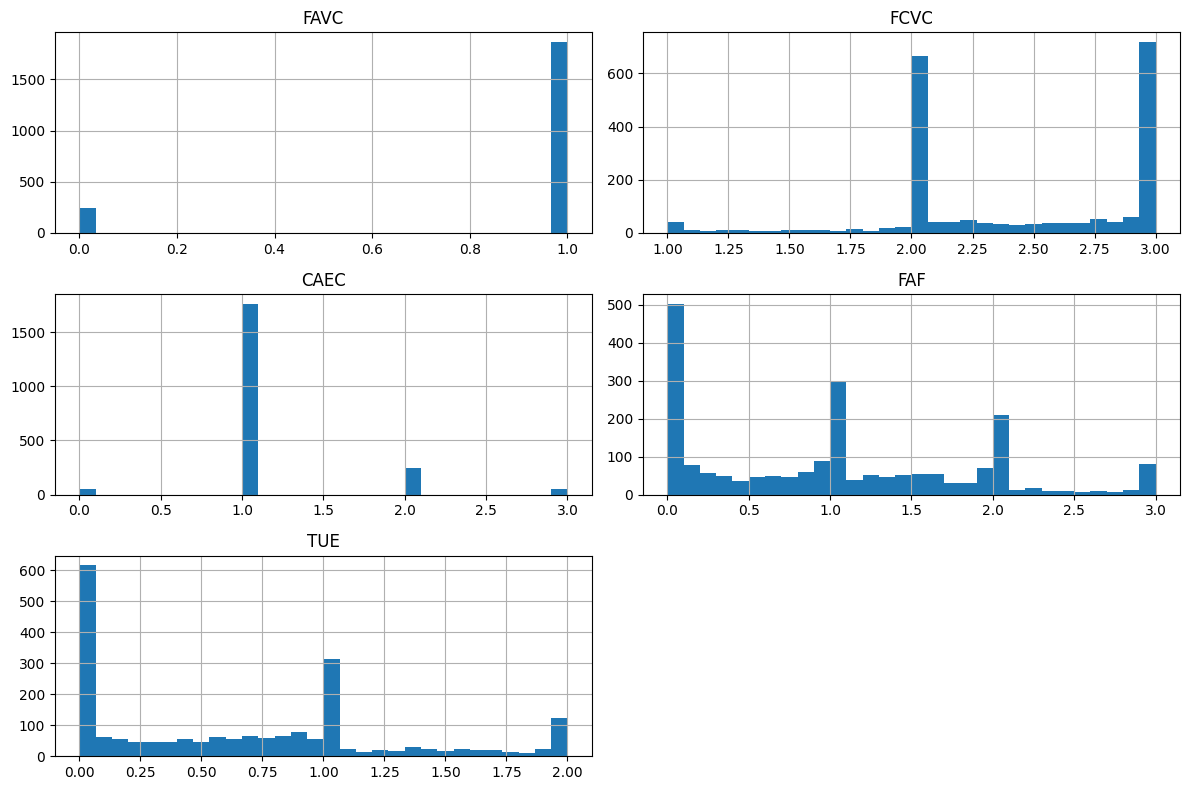

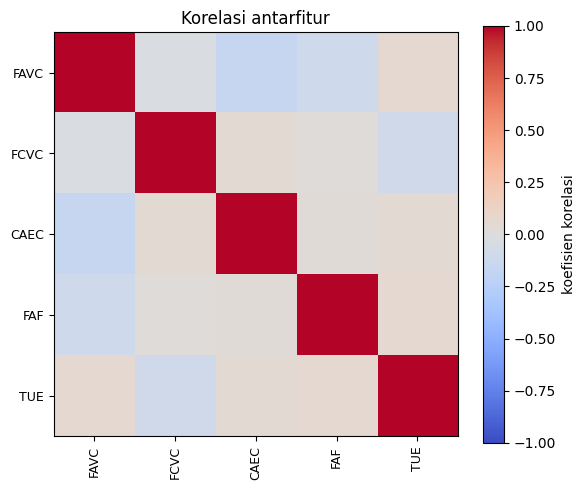

Pasangan berkorelasi di atas 0,9: tidak ada
Fitur kembar membuat satu dimensi dihitung dua kali oleh K-Means.
Varian 3 menguji pengaruh memisahkan fitur pola makan dan fitur aktivitas.


In [ ]:
num.hist(figsize=(12, 8), bins=30)
plt.tight_layout(); plt.savefig('gambar/eda_distribusi.png', dpi=110); plt.show()

kor = num.corr()
plt.figure(figsize=(6, 5))
plt.imshow(kor, cmap='coolwarm', vmin=-1, vmax=1)
plt.colorbar(label='koefisien korelasi')
plt.xticks(range(len(kor)), kor.columns, rotation=90, fontsize=9)
plt.yticks(range(len(kor)), kor.columns, fontsize=9)
plt.title('Korelasi antarfitur'); plt.tight_layout()
plt.savefig('gambar/eda_korelasi.png', dpi=110); plt.show()

kolom_num = num.columns.tolist()
tinggi = [(a, b, round(float(kor.loc[a, b]), 3))
          for i, a in enumerate(kolom_num) for b in kolom_num[i+1:]
          if abs(kor.loc[a, b]) > 0.9]
print('Pasangan berkorelasi di atas 0,9:', tinggi if tinggi else 'tidak ada')
print('Fitur kembar membuat satu dimensi dihitung dua kali oleh K-Means.')
print('Varian 3 menguji pengaruh memisahkan fitur pola makan dan fitur aktivitas.')

## 1.6 Empat jawaban yang dinilai

1. **Satu baris data pada dataset ini mewakili apa?**
   Satu baris mewakili **satu responden (satu individu)**. Tiap baris memuat kebiasaan makan, aktivitas fisik, dan data fisik orang tersebut. Karena satu baris sudah satu orang, **data tidak perlu diagregasi** lebih dulu. Catatan: dataset ini berisi 2.111 baris, dan menurut dokumentasinya sebagian besar (sekitar 77%) dibangkitkan secara sintetis dengan SMOTE. Ini terlihat dari nilai pecahan pada kolom skala yang seharusnya bilangan bulat, misalnya `FCVC`, `FAF`, dan `TUE`.

2. **Dua kolom dengan skala paling jauh berbeda, beserta min dan max-nya:**
   Di antara lima fitur proposal, `FAVC` (setelah dikodekan: min 0, max 1) dan `FCVC` atau `FAF` (min 1 atau 0, max 3). Rasio max terbesar terhadap terkecil hanya sekitar 3 kali, jauh lebih kecil daripada bila `Weight` (39 sampai 173 kg) ikut dipakai. `TUE` berskala 0 sampai 2, dan `CAEC` yang dikodekan 0 sampai 3. Karena selisihnya kecil, pengaruh penskalaan diuji sebagai tugas Varian 2, bukan diasumsikan.

3. **Kolom mana yang dibuang karena berupa identitas, dan mengapa:**
   **Tidak ada kolom identitas** (tidak ada nomor responden; kolom kategorik paling banyak hanya punya 7 nilai unik dari 2.111 baris), sehingga `ID_COL = None`. Yang dibuang adalah **12 kolom di luar proposal**: `Gender`, `Age`, `Height`, `Weight`, `family_history_with_overweight`, `NCP`, `SMOKE`, `CH2O`, `SCC`, `CALC`, `MTRANS`, dan `NObeyesdad`. Alasannya, pertanyaan analitik kelompok adalah pengelompokan responden berdasarkan **pola makan dan aktivitas**, sehingga hanya `FAVC`, `FCVC`, `CAEC`, `FAF`, dan `TUE` yang dipakai. Membuang `Weight`, `Height`, dan `NObeyesdad` juga mencegah klaster hanya mengulang kategori berat badan, karena label itu dihitung dari IMT (`Weight / Height²`).

4. **Adakah fitur yang nilainya justru merupakan jawaban yang ingin dicari?**
   **Ya, `NObeyesdad`**, yaitu tujuh kelas tingkat berat badan (Insufficient_Weight sampai Obesity_Type_III). Pada dataset aslinya kolom ini adalah label untuk klasifikasi. Pada proposal kolom target diisi "Tidak ada" karena metodenya klastering, sehingga kolom ini tidak ikut membentuk klaster. Kolom ini dapat dipakai nanti hanya sebagai pembanding saat menafsirkan klaster, bukan sebagai masukan.

>

## 1.7 Membersihkan

Urutannya: buang duplikat, pisahkan identitas, pilih lima fitur proposal dan **kodekan** `FAVC` serta `CAEC` menjadi angka, imputasi median, lalu **batasi** pencilan dengan IQR hanya pada fitur numerik kontinu (`FCVC`, `FAF`, `TUE`).

Pencilan **dibatasi, bukan dibuang**. Pada data perilaku pelanggan, baris pencilan justru sering merupakan segmen yang ingin ditemukan — pelanggan bersaldo sangat besar, misalnya. Membuang barisnya sama dengan menghapus segmen itu sebelum K-Means melihatnya. Membatasi nilainya menahan pengaruh berlebih tanpa menghilangkan barisnya.
`FAVC` dan `CAEC` **tidak ikut dibatasi dengan IQR**. Keduanya diskret dan sangat condong ke satu nilai (kebanyakan responden `Sometimes` pada `CAEC`), sehingga IQR-nya nol dan pembatasan akan menghapus kategori minoritas yang sah, misalnya `Frequently` dan `Always`.


In [ ]:
from alat import FITUR, kodekan

df = df_mentah.copy()

sebelum = len(df)
df = df.drop_duplicates().reset_index(drop=True)
print(f'Duplikat dibuang: {sebelum - len(df)} baris')

ids = None
if ID_COL in df.columns:
    ids = df[ID_COL].copy()
    df = df.drop(columns=[ID_COL])
    print(f'Kolom identitas {ID_COL} dipisahkan')

# Pilih lima fitur proposal, buang sisanya
dibuang = [c for c in df.columns if c not in FITUR]
print(f'Kolom di luar proposal dibuang ({len(dibuang)}):', dibuang)

# Kodekan FAVC (biner) dan CAEC (ordinal 0-3) agar bisa dipakai K-Means
df = kodekan(df)
kolom = df.columns.tolist()
print('Fitur dipakai:', kolom)
print('  FAVC: no=0, yes=1 | CAEC: no=0, Sometimes=1, Frequently=2, Always=3')

print('\nImputasi median:')
for c in kolom:
    n = int(df[c].isna().sum())
    if n:
        med = float(df[c].median())
        df[c] = df[c].fillna(med)
        print(f'  {c:<10} {n:>5} nilai -> median {med:,.2f}')
print('  (tidak ada nilai hilang bila daftar di atas kosong)')

# IQR hanya untuk fitur numerik kontinu; FAVC dan CAEC diskret, tidak dibatasi
KOLOM_KLIP = ['FCVC', 'FAF', 'TUE']
total = 0
print('\nPencilan dibatasi dengan IQR (bukan dibuang):')
for c in KOLOM_KLIP:
    q1, q3 = df[c].quantile(0.25), df[c].quantile(0.75)
    iqr = q3 - q1
    bawah, atas = q1 - IQR_PENGALI*iqr, q3 + IQR_PENGALI*iqr
    kena = int(((df[c] < bawah) | (df[c] > atas)).sum())
    if kena:
        total += kena
        df[c] = df[c].clip(bawah, atas)
    print(f'  {c:<10} {kena:>5} nilai ({kena/len(df)*100:5.2f}%)')
print('Total nilai dibatasi:', total)
print('Bila satu kolom lebih dari 25% nilainya dibatasi, periksa apakah')
print('struktur klasternya masih ada. Bila Silhouette anjlok, naikkan IQR_PENGALI.')


Duplikat dibuang: 24 baris
Kolom di luar proposal dibuang (12): ['Gender', 'Age', 'Height', 'Weight', 'family_history_with_overweight', 'NCP', 'SMOKE', 'CH2O', 'SCC', 'CALC', 'MTRANS', 'NObeyesdad']
Fitur dipakai: ['FAVC', 'FCVC', 'CAEC', 'FAF', 'TUE']
  FAVC: no=0, yes=1 | CAEC: no=0, Sometimes=1, Frequently=2, Always=3

Imputasi median:
  (tidak ada nilai hilang bila daftar di atas kosong)

Pencilan dibatasi dengan IQR (bukan dibuang):
  FCVC           0 nilai ( 0.00%)
  FAF            0 nilai ( 0.00%)
  TUE            0 nilai ( 0.00%)
Total nilai dibatasi: 0
Bila satu kolom lebih dari 25% nilainya dibatasi, periksa apakah
struktur klasternya masih ada. Bila Silhouette anjlok, naikkan IQR_PENGALI.


### Pemeriksaan hasil pembatasan

Sel di bawah membandingkan Silhouette (k = 2 sampai 6) sebelum dan sesudah pembatasan. Baca angka **pada keluaran sel 1.7** lebih dulu: bila tidak ada nilai yang dibatasi pada `FCVC`, `FAF`, dan `TUE`, kedua baris Silhouette akan sama persis, dan itu wajar. Bila ada kolom yang dibatasi lebih dari 25%, tulis di sini temuan dan keputusan kelompok.


In [ ]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from sklearn.preprocessing import StandardScaler

mentah_num = kodekan(df_mentah.drop_duplicates().reset_index(drop=True))[kolom]

def sil(data):
    X = StandardScaler().fit_transform(data)
    return [round(float(silhouette_score(
        X, KMeans(k, n_init=10, random_state=SEED).fit_predict(X))), 3)
        for k in range(2, 7)]

print('Silhouette untuk k = 2 sampai 6')
print('  tanpa pembatasan  :', sil(mentah_num))
print('  IQR 1,5 (dipakai) :', sil(df[kolom]))


Silhouette untuk k = 2 sampai 6
  tanpa pembatasan  : [0.406, 0.247, 0.264, 0.281, 0.288]
  IQR 1,5 (dipakai) : [0.406, 0.247, 0.264, 0.281, 0.288]


## 1.8 Menyimpan dan membagikan data bersih

In [ ]:
keluar = df.copy()
if ids is not None:
    keluar.insert(0, ID_COL, ids.to_numpy())
keluar.to_csv('data/data_bersih.csv', index=False)
print('Tersimpan: data/data_bersih.csv', keluar.shape)

from google.colab import files
files.download('data/data_bersih.csv')
files.download('gambar/eda_distribusi.png')
files.download('gambar/eda_korelasi.png')
print()
print('Langkah berikutnya:')
print('  1. Bagikan data_bersih.csv ke kedua anggota lain.')
print('  2. Commit data_bersih.csv ke folder data/ pada repositori kelompok.')
print('  3. Commit kedua gambar ke folder gambar/.')
print('  4. Unduh notebook ini: File -> Download -> Download .ipynb,')
print('     beri nama 01_penyiapan_data.ipynb, commit ke folder notebook/.')

Tersimpan: data/data_bersih.csv (2087, 5)


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>


Langkah berikutnya:
  1. Bagikan data_bersih.csv ke kedua anggota lain.
  2. Commit data_bersih.csv ke folder data/ pada repositori kelompok.
  3. Commit kedua gambar ke folder gambar/.
  4. Unduh notebook ini: File -> Download -> Download .ipynb,
     beri nama 01_penyiapan_data.ipynb, commit ke folder notebook/.


## 1.9 Pernyataan urutan kerja

Ini salah satu luaran yang dinilai. Salin paragraf berikut ke `README.md`, **periksa kebenarannya terhadap yang benar-benar Anda jalankan**, lalu sesuaikan bila berbeda.

> Pada cabang klastering tidak ada pemisahan data latih dan data uji, karena tidak ada label yang diuji. Pembersihan dilakukan sekali atas seluruh data: buang duplikat (24 baris), pilih lima fitur sesuai proposal (`FAVC`, `FCVC`, `CAEC`, `FAF`, `TUE`) dan buang 12 kolom lainnya termasuk label `NObeyesdad` (dataset ini tidak punya kolom identitas), kodekan `FAVC` (no=0, yes=1) dan `CAEC` (no=0, Sometimes=1, Frequently=2, Always=3), imputasi median (tidak ada nilai hilang), lalu pembatasan pencilan dengan IQR 1,5 hanya pada `FCVC`, `FAF`, dan `TUE`. Hasilnya disimpan sebagai `data_bersih.csv` dan dipakai ketiga varian apa adanya. Penskalaan tidak dilakukan pada tahap pembersihan, melainkan di dalam tiap varian dan sekali lagi saat model final dilatih: `StandardScaler` di-fit satu kali pada data bersih, lalu disimpan sebagai `scaler.pkl` dan dipakai aplikasi web dengan `transform`, bukan `fit_transform`. Aplikasi web memakai fungsi `kodekan` yang sama dari `alat.py` agar masukan pengguna (ya/tidak dan kadang-kadang/sering/selalu) diubah ke angka dengan cara yang sama seperti di notebook. One-hot tidak dipakai; `CAEC` diperlakukan ordinal dengan asumsi jarak antartingkat sama, yang perlu disebut sebagai keterbatasan.

**Mengapa berbeda dari cabang klasifikasi.** Pada k-NN urutan wajibnya adalah bersihkan, pisahkan data, baru skalakan — penskalaan sebelum pemisahan membuat statistik data uji bocor ke pelatihan. Pada klastering tidak ada pemisahan, sehingga yang dijaga bukan kebocoran antar-himpunan, melainkan **kesamaan skala dan pengodean antara notebook dan aplikasi web**.

## Checklist Bagian 1

- [ ] `data/raw.csv` ada dan tidak pernah diubah lagi
- [ ] `data/data_bersih.csv` (2.087 baris, 5 kolom) ada sebagai berkas di repositori, bukan hanya sel notebook
- [ ] `gambar/eda_distribusi.png` dan `gambar/eda_korelasi.png` ter-commit
- [ ] Empat jawaban di 1.6 sudah ditulis sendiri
- [ ] Pernyataan urutan kerja sudah masuk `README.md` dan sudah diperiksa
- [ ] Kedua anggota lain sudah menerima `data_bersih.csv`
- [ ] Mulai sekarang tidak ada lagi yang membersihkan data sendiri-sendiri
